# SORDINO (zero echo time) electrical stimulation fMRI: stitching and preprocessing

1. Convert the raw Bruker functional scans (same session and subject, acquired back-to-back with identical acquisition parameters) to NIfTI and concatenate them in the given order. The converted NIfTIs carry a wrong TR (1 s, Bruker only stores the 0.75 ms spoke time), so the stitched series is written with the real volume TR (`PVM_ScanTime / PVM_NRepetitions`, e.g. 2.4 s). By default no volumes are dropped, because the 10 s of dummy scans before every sordino scan already bring the signal into steady state; volumes can still be dropped if a scan shows a start-up transient.
2. Motion-correct the stitched series once against a single reference volume (the middle volume of the whole series).
3. Draw the brain mask on the middle volume, compute the mean motion-corrected image and process the structural scan.

Sordino is a 3D radial acquisition without echo-planar readout, so there is no distortion correction in this notebook and no slices. A volume takes `NPro x 0.75 ms` (3200 spokes: 2.4 s). The stimulation paradigm is not stored in the method file: the scanner only sends a trigger pulse to the stimulator at the start of the scan and at the start of every trigger block (`NVolumesPerBlock`). The trigger blocks of every scan are printed below and saved in `session.json` for the analysis.

Optionally (step *Normalise Scan Levels*, off by default), the scans are scaled so that the signal level continues across the stitching points, which removes steps between scans caused by e.g. a change of the head position relative to the coil. One factor per scan is applied (`scan_normalization.csv`), so changes within a scan stay untouched. Real differences between scans, e.g. a lasting change after the stimulation, are removed as well, so keep the baseline of an analysis in the same scan as its signal window when this is used. The settings are part of the folder name (`..._drop10_norm`), so runs with different settings never overwrite each other.

Enter the functional scan numbers in acquisition order. `scan_boundaries.csv` in the functional analysis folder records the volume range of each original scan.

Every step is skipped when its output already exists and is newer than its inputs, so the notebook can simply be run again. Tick *Force re-run* to recompute everything. The results go to the stitched folder (`func.nii.gz`, `mc_func.nii.gz`, masks) and to `<analysis folder name>` inside it (`mean_mc_func.nii.gz`, `session.json`). `session.json` is loaded by `mol_fMRI_sordino_analysis.ipynb`, which continues from here.

In [13]:
import electric_stim_helpers, electric_stim_session, sordino_helpers
from electric_stim_helpers import *
from electric_stim_session import *
from sordino_helpers import *
from fmri_paths import get_fmri_root

In [15]:
def int_widget(value, desc):
    return widgets.IntText(value=value, description=desc, layout=INPUT_LAYOUT, style={'description_width': DESC_WIDTH})


def print_selected_pipeline_steps():
    print("\nPIPELINE STEP SELECTION SUMMARY")
    print("-" * 40)
    for step in PIPELINE_STEPS:
        print(f"[{'✓' if checkboxes[step['key']].value else ' '}] {step['name']}")
    print("-" * 40)


def is_step_enabled(step_key):
    return checkboxes.get(step_key, None) and checkboxes[step_key].value


PIPELINE_STEPS = [
    {"name": "Bruker → NIfTI + Stitching", "key": "bruker_to_nifti"},
    {"name": "Motion Correction", "key": "motion_correction"},
    {"name": "Masking", "key": "masking_file"},
    {"name": "Normalise Scan Levels", "key": "scan_normalization", "default": False}]

checkboxes = {step["key"]: widgets.Checkbox(value=step.get("default", True), description=step["name"], indent=False) for step in PIPELINE_STEPS}

display(widgets.Box(list(checkboxes.values()), layout=widgets.Layout(display="flex", flex_flow="row wrap", align_items="flex-start", gap="10px")))

Box(children=(Checkbox(value=True, description='Bruker → NIfTI + Stitching', indent=False), Checkbox(value=Tru…

In [16]:
## Make sure what functions are selected to run in the pipeline
print_selected_pipeline_steps()

# Data root: environment variable FMRI_ROOT, fmri_root.txt or the folder containing this repository (see fmri_paths.py)
FMRI_ROOT = get_fmri_root()

## Choosing the raw data that needs to be analysed
root_location = f"{FMRI_ROOT}/RawData"
selected_folder = FileChooser(root_location, layout=widgets.Layout(width='1080px'))
selected_folder.show_only_dirs = True
display(selected_folder)


PIPELINE STEP SELECTION SUMMARY
----------------------------------------
[✓] Bruker → NIfTI + Stitching
[✓] Motion Correction
[✓] Masking
[✓] Normalise Scan Levels
----------------------------------------


FileChooser(path='/Volumes/pschmidt/fmri_analysis/RawData', filename='', title='', show_hidden=False, select_d…

In [17]:
in_path = Path(selected_folder.selected_path)
print(f"Our Raw Data is located in the path {in_path}")
subject_id = extract_subject_id(in_path)

# ---------- Common styles ----------
INPUT_LAYOUT = widgets.Layout(width="280px", flex="0 0 auto")
ROW_LAYOUT = widgets.Layout(width="100%", justify_content="space-between", align_items="center", padding="12px", border="3px solid #444", border_radius="10px", background_color="#1e1e1e")
DESC_WIDTH = "220px"

# ---------- Widgets (KEEP REFERENCES) ----------
func_scan_numbers_entered = widgets.Text(value="", placeholder="e.g. 31 or 28, 31, 32", description="Functional Scans (in order):", layout=INPUT_LAYOUT, style={'description_width': DESC_WIDTH})
struct_scan_number_entered = int_widget(10, "Structural Scan:")
mask_source_dir_entered = widgets.Text(value="", placeholder="optional", description="Reuse masks from folder:", layout=INPUT_LAYOUT, style={'description_width': DESC_WIDTH})

drop_vols_entered = int_widget(0, "Volumes to drop per scan:")

row = widgets.HBox([func_scan_numbers_entered, struct_scan_number_entered, drop_vols_entered], layout=ROW_LAYOUT)
analysis_name_entered = widgets.Text(value="analysis", description="Analysis folder name:", layout=INPUT_LAYOUT, style={'description_width': DESC_WIDTH})
force_rerun_entered = widgets.Checkbox(value=False, description="Force re-run of finished steps", indent=False)
row_masks = widgets.HBox([mask_source_dir_entered, analysis_name_entered, force_rerun_entered], layout=ROW_LAYOUT)
display(row, row_masks)

Our Raw Data is located in the path /Volumes/pschmidt/fmri_analysis/RawData/Sordino_converted/20261026_141809_RGRO_261026_0224_RN_SD_468_MMP9_Rat_BW_Elect_stim_1_1


In [19]:
func_scan_numbers = [s for s in re.split(r"[,\s]+", func_scan_numbers_entered.value.strip()) if s]
if not func_scan_numbers:
    raise ValueError("Enter at least 1 functional scan number, e.g. '31' or '28, 31, 32' (several scans are stitched in the given order).")
func_scan_label = "-".join(func_scan_numbers)
struct_scan_number = str(struct_scan_number_entered.value)
mask_source_dir = mask_source_dir_entered.value.strip() or None

drop_vols = max(0, int(drop_vols_entered.value))
normalise_enabled = bool(is_step_enabled("scan_normalization"))

print_statement(f"Subject under analysis is {subject_id} for Functional Scans {', '.join(func_scan_numbers)} (stitched in this order) and Structural Scan Number {struct_scan_number}", bcolors.NOTIFICATION)
print_statement(f"Dropping the first {drop_vols} volumes of every scan; scan level normalisation {'on' if normalise_enabled else 'off'}.", bcolors.NOTIFICATION)
# # Parameters extraction for structural and functional files

params_struct = func_param_extract(Path(in_path) / struct_scan_number,export_env=True)
sequence_name_struct = params_struct["SequenceName"]

params_all = {num: sordino_param_extract(Path(in_path) / num) for num in func_scan_numbers}
params_func = params_all[func_scan_numbers[0]]
sequence_name_func = params_func["SequenceName"]

# Stitching assumes identical acquisition parameters across scans; scans with block triggers can differ by a dummy spoke per volume (0.75 ms)
for num, p in params_all.items():
    if not p["is_sordino"]:
        print_statement(f"Scan {num} is not a sordino scan (method {p['Method']}).", bcolors.FAIL)
    if p["SequenceName"] != sequence_name_func or abs(p["VolTR"] - params_func["VolTR"]) > 0.01:
        print_statement(f"Scan {num} differs from scan {func_scan_numbers[0]} in sequence name or TR.", bcolors.FAIL)

print_header("Sordino scans: volume TR and trigger blocks", bcolors.HEADER)
for num, p in params_all.items():
    trigger_text = (f"start-of-scan trigger: {'yes' if p['StartOfScanTrigger'] else 'no'}, {len(p['block_onsets'])} block triggers every {sorted(set(p['volumes_per_block']))} volumes"
                    if p["BlockTriggerMode"] else "no triggers")
    print_statement(f"Scan {num}: {p['NoOfRepetitions']} volumes, TR {p['VolTR']:.5f} s, {trigger_text}", bcolors.NOTIFICATION)


# Setting up path for storing analysed data overall, structural data, functional data and processed functional data
# Analysed data overall
parts = list(in_path.parts)
parts[parts.index("RawData")] = "AnalysedData"
analysed_base = Path(*parts).parent
analysed_path = analysed_base / subject_id

# Structural and Functional data
analysed_struct_dir = Path(analysed_path) / f"{struct_scan_number}{sequence_name_struct}"
# the processing options are part of the folder name so results with different options never mix
dir_suffix = (f"_drop{drop_vols}" if drop_vols else "") + ("_norm" if normalise_enabled else "")
analysed_func_dir = Path(analysed_path) / f"stitched_{func_scan_label}_{sequence_name_func}{dir_suffix}"

# processed functional data: a fixed folder, so a later run (or the analysis notebook) finds the same files
analysis_dir = analysed_func_dir / (analysis_name_entered.value.strip() or "analysis")
analysis_dir.mkdir(parents=True, exist_ok=True)
electric_stim_session.FORCE_RERUN = force_rerun_entered.value

# path for raw structural and functional data 
path_raw_struct = os.path.join(in_path, struct_scan_number)
path_raw_func = ", ".join(os.path.join(in_path, num) for num in func_scan_numbers)

# Display of variables and paths in tabular form
var_vals = [
            ['Location of all Raw Data', 'root_location', root_location],
            ['Location of Raw Data to be analysed', 'in_path', in_path],
            ['Location of Raw Structural Data', 'path_raw_struct', path_raw_struct],
            ['Location of Raw Functional Data', 'path_raw_func', path_raw_func],
            ['Location of analysed structural data', 'analysed_struct_dir', analysed_struct_dir],
            ['Location of analysed functional data', 'analysed_func_dir', analysed_func_dir],
            ['Location of final processed functional data', 'analysis_dir', analysis_dir]
            ]

# pd.set_option('display.max_colwidth', 500)  # or 199
df = pd.DataFrame(var_vals, columns=['Purpose', 'Variable Name', 'Value'], index=['a', 'b', 'c', 'd', 'e', 'f', 'g'])
print(tabulate(df, headers='keys', tablefmt='psql'))

Subject under analysis is RGRO_261026_0224_RN_SD_468 for Functional Scans 71 (stitched in this order) and Structural Scan Number 37
Dropping the first 0 volumes of every scan; scan level normalisation on.

**************************************************************************************************************************************
                                             Sordino scans: volume TR and trigger blocks                                              
**************************************************************************************************************************************

Scan 71: 240 volumes, TR 4.99044 s, no triggers
+----+---------------------------------------------+---------------------+------------------------------------------------------------------------------------------------------------------------------------+
|    | Purpose                                     | Variable Name       | Value                                                    

# Converting Functional Scans into NIFTI and Stitching them

In [20]:
print_statement(f"Analysed Data Path: {analysed_func_dir}", bcolors.NOTIFICATION)
analysed_func_dir.mkdir(parents=True, exist_ok=True)
os.chdir(analysed_func_dir)

if is_step_enabled("bruker_to_nifti"):
    print_header("Converting Bruker to NIFTI and stitching: Functional Data", bcolors.HEADER)

    stitched_file = analysed_func_dir / "func.nii.gz"

    if stitched_file.exists():
        print_statement("Stitched NIfTI file already exists. Skipping conversion and stitching.", bcolors.OKGREEN)
    else:
        scan_files = []
        for num in func_scan_numbers:
            work_dir = analysed_func_dir / "converted_raw" / f"scan_{num}"
            out_name = f"{num}_func_raw.nii.gz"
            if (work_dir / out_name).exists():
                print_statement(f"Scan {num} already converted. Skipping conversion.", bcolors.OKGREEN)
            else:
                bruker_scan_to_nifti(in_path, num, work_dir, out_name)
            if drop_vols:
                trimmed_name = f"{num}_func_raw_drop{drop_vols}.nii.gz"
                if not (work_dir / trimmed_name).exists():
                    drop_first_volumes(work_dir / out_name, drop_vols, work_dir / trimmed_name)
                out_name = trimmed_name
            scan_files.append(str((work_dir / out_name).resolve()))

        per_scan_volumes = [n_volumes(f) for f in scan_files]
        if stitched_file.exists() and not force_rerun_entered.value:
            print_statement(f"{stitched_file.name} already exists. Skipping stitching.", bcolors.OKGREEN)
        else:
            # volume TR of the stitched series: volume-weighted mean (scans with block triggers have a dummy spoke per volume, +0.75 ms)
            stitched_tr = sum(params_all[num]["VolTR"] * n for num, n in zip(func_scan_numbers, per_scan_volumes)) / sum(per_scan_volumes)
            merge_with_tr(scan_files, stitched_file.name, stitched_tr)
        write_boundaries_csv(scan_files, per_scan_volumes, "scan_boundaries.csv")

else:
    print_statement("⏭️ Data Conversion Step not executed, May cause trouble in running further analysis", bcolors.NOTIFICATION)

input_name_for_next_step = "func"

Analysed Data Path: /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm

**************************************************************************************************************************************
                                      Converting Bruker to NIFTI and stitching: Functional Data                                       
**************************************************************************************************************************************

Converting raw Bruker scan 71 (/Volumes/pschmidt/fmri_analysis/RawData/Sordino_converted/20261026_141809_RGRO_261026_0224_RN_SD_468_MMP9_Rat_BW_Elect_stim_1_1/71) -> NIfTI...


/Users/pschmidt/miniforge3/envs/fmri/lib/python3.11/site-packages/brkraw/lib/loader.py:951: UserWarning: Unexpected version[VisuVersion];8
  warnings.warn('Unexpected version[VisuVersion];{}'.format(version), UserWarning)


NifTi file is generated... [RGRO_261026_0224_RN_SD_468_1-71-1-sordino-(E71)]
[OK] Raw Bruker scan 71 converted -> /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/converted_raw/scan_71/71_func_raw.nii.gz
[OK] Scans concatenated -> func.nii.gz (TR 4.9904 s)

**************************************************************************************************************************************
                                       Scan boundaries in stitched series (0-based, inclusive)                                        
**************************************************************************************************************************************

Scan 1: volumes 0-239 (240 vols) <- /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/converted_raw/scan_71/71_func_raw.nii.gz


# Brain Mask

In [24]:
os.environ["FSLOUTPUTTYPE"] = "NIFTI_GZ"

tr = float(subprocess.run(["fslval", "func.nii.gz", "pixdim4"], capture_output=True, text=True, check=True).stdout)  # real volume TR written at stitching
n_vols = n_volumes("func.nii.gz")

# Middle volume of the whole stitched series: reference for motion correction and the image the mask is drawn on
run_step(["middle_vol.nii.gz"], ["func.nii.gz"], extract_middle_volume, "func.nii.gz", int(n_vols / 2), "middle_vol.nii.gz", 1)

mask_file = os.path.join(analysed_func_dir, "mask_mean_mc_func.nii.gz")

if is_step_enabled("masking_file"):
    # Only valid if the stitched scans share identical geometry with the mask source scan
    mask_src = Path(mask_source_dir) / "mask_mean_mc_func.nii.gz" if mask_source_dir else None
    if not os.path.exists(mask_file) and mask_src is not None and mask_src.exists():
        shutil.copyfile(mask_src, mask_file)
        print_statement(f"[OK] Reused mask from {mask_src}", bcolors.OKGREEN)

    if os.path.exists(mask_file):
        print_statement(f"Mask Image ({mask_file}) exists.", bcolors.OKGREEN)
    else:
        print_statement("Mask Image does not exist. Please create the mask and save it as mask_mean_mc_func.nii.gz", bcolors.FAIL)
        subprocess.run(["fsleyes", "middle_vol.nii.gz"])
        require_files([mask_file], "Save the brain mask as mask_mean_mc_func.nii.gz in the functional analysis folder.")
else:
    print_statement("⏭️ Masks not generated, will not get cleaned data in further pipeline", bcolors.NOTIFICATION)

[OK] Intended Volumes extracted.
Mask Image (/Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/mask_mean_mc_func.nii.gz) exists.


# Scan Level Normalisation (optional)

Scales every scan so that its signal level continues the neighbouring scan (see the description at the top), starting from the scan that contains the middle volume, which is the motion correction reference. Needs the brain mask. The normalised series `func_norm.nii.gz` is the input of the motion correction; the factors are in `scan_normalization.csv`.

In [25]:
if normalise_enabled:
    print_header("Normalising the signal level of the scans", bcolors.HEADER)
    require_files([mask_file], "Scan level normalisation needs the brain mask: tick Masking and save the mask first.")
    run_step(["func_norm.nii.gz", "scan_normalization.csv"], ["func.nii.gz", mask_file], normalise_scan_levels,
             "func.nii.gz", mask_file, read_scan_ranges(analysed_func_dir), int(n_vols / 2), "func_norm.nii.gz", "scan_normalization.csv")
else:
    print_statement("⏭️ Scan level normalisation not selected", bcolors.NOTIFICATION)


**************************************************************************************************************************************
                                              Normalising the signal level of the scans                                               
**************************************************************************************************************************************


**************************************************************************************************************************************
                                        Scan level normalisation (factor applied to each scan)                                        
**************************************************************************************************************************************

 scan  start_volume  end_volume  factor  level_first_vols  level_last_vols  anchor
    1             0         239     1.0        99725944.0      100389328.0    True
[OK] Normalised seri

# Applying Motion Correction in Raw Functional Data and Plotting Motion Parameters


**************************************************************************************************************************************
                           Applying Motion Correction on raw functional data and plotting motion parameters                           
**************************************************************************************************************************************

261105-17:30:43,94 nipype.interface INFO:
	 stderr 2026-11-05T17:30:43.094472:++ 3dvolreg: AFNI version=AFNI_26.2.06 (Sep  3 2026) [64-bit]
261105-17:30:43,95 nipype.interface INFO:
	 stderr 2026-11-05T17:30:43.094472:++ Authored by: RW Cox
261105-17:30:43,105 nipype.interface INFO:
	 stderr 2026-11-05T17:30:43.105874:++ Reading in base dataset /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/middle_vol.nii.gz
261105-17:30:43,158 nipype.interface INFO:
	 stderr 2026-11-05T17:30:43.158117:++ Reading input dataset /Volumes/

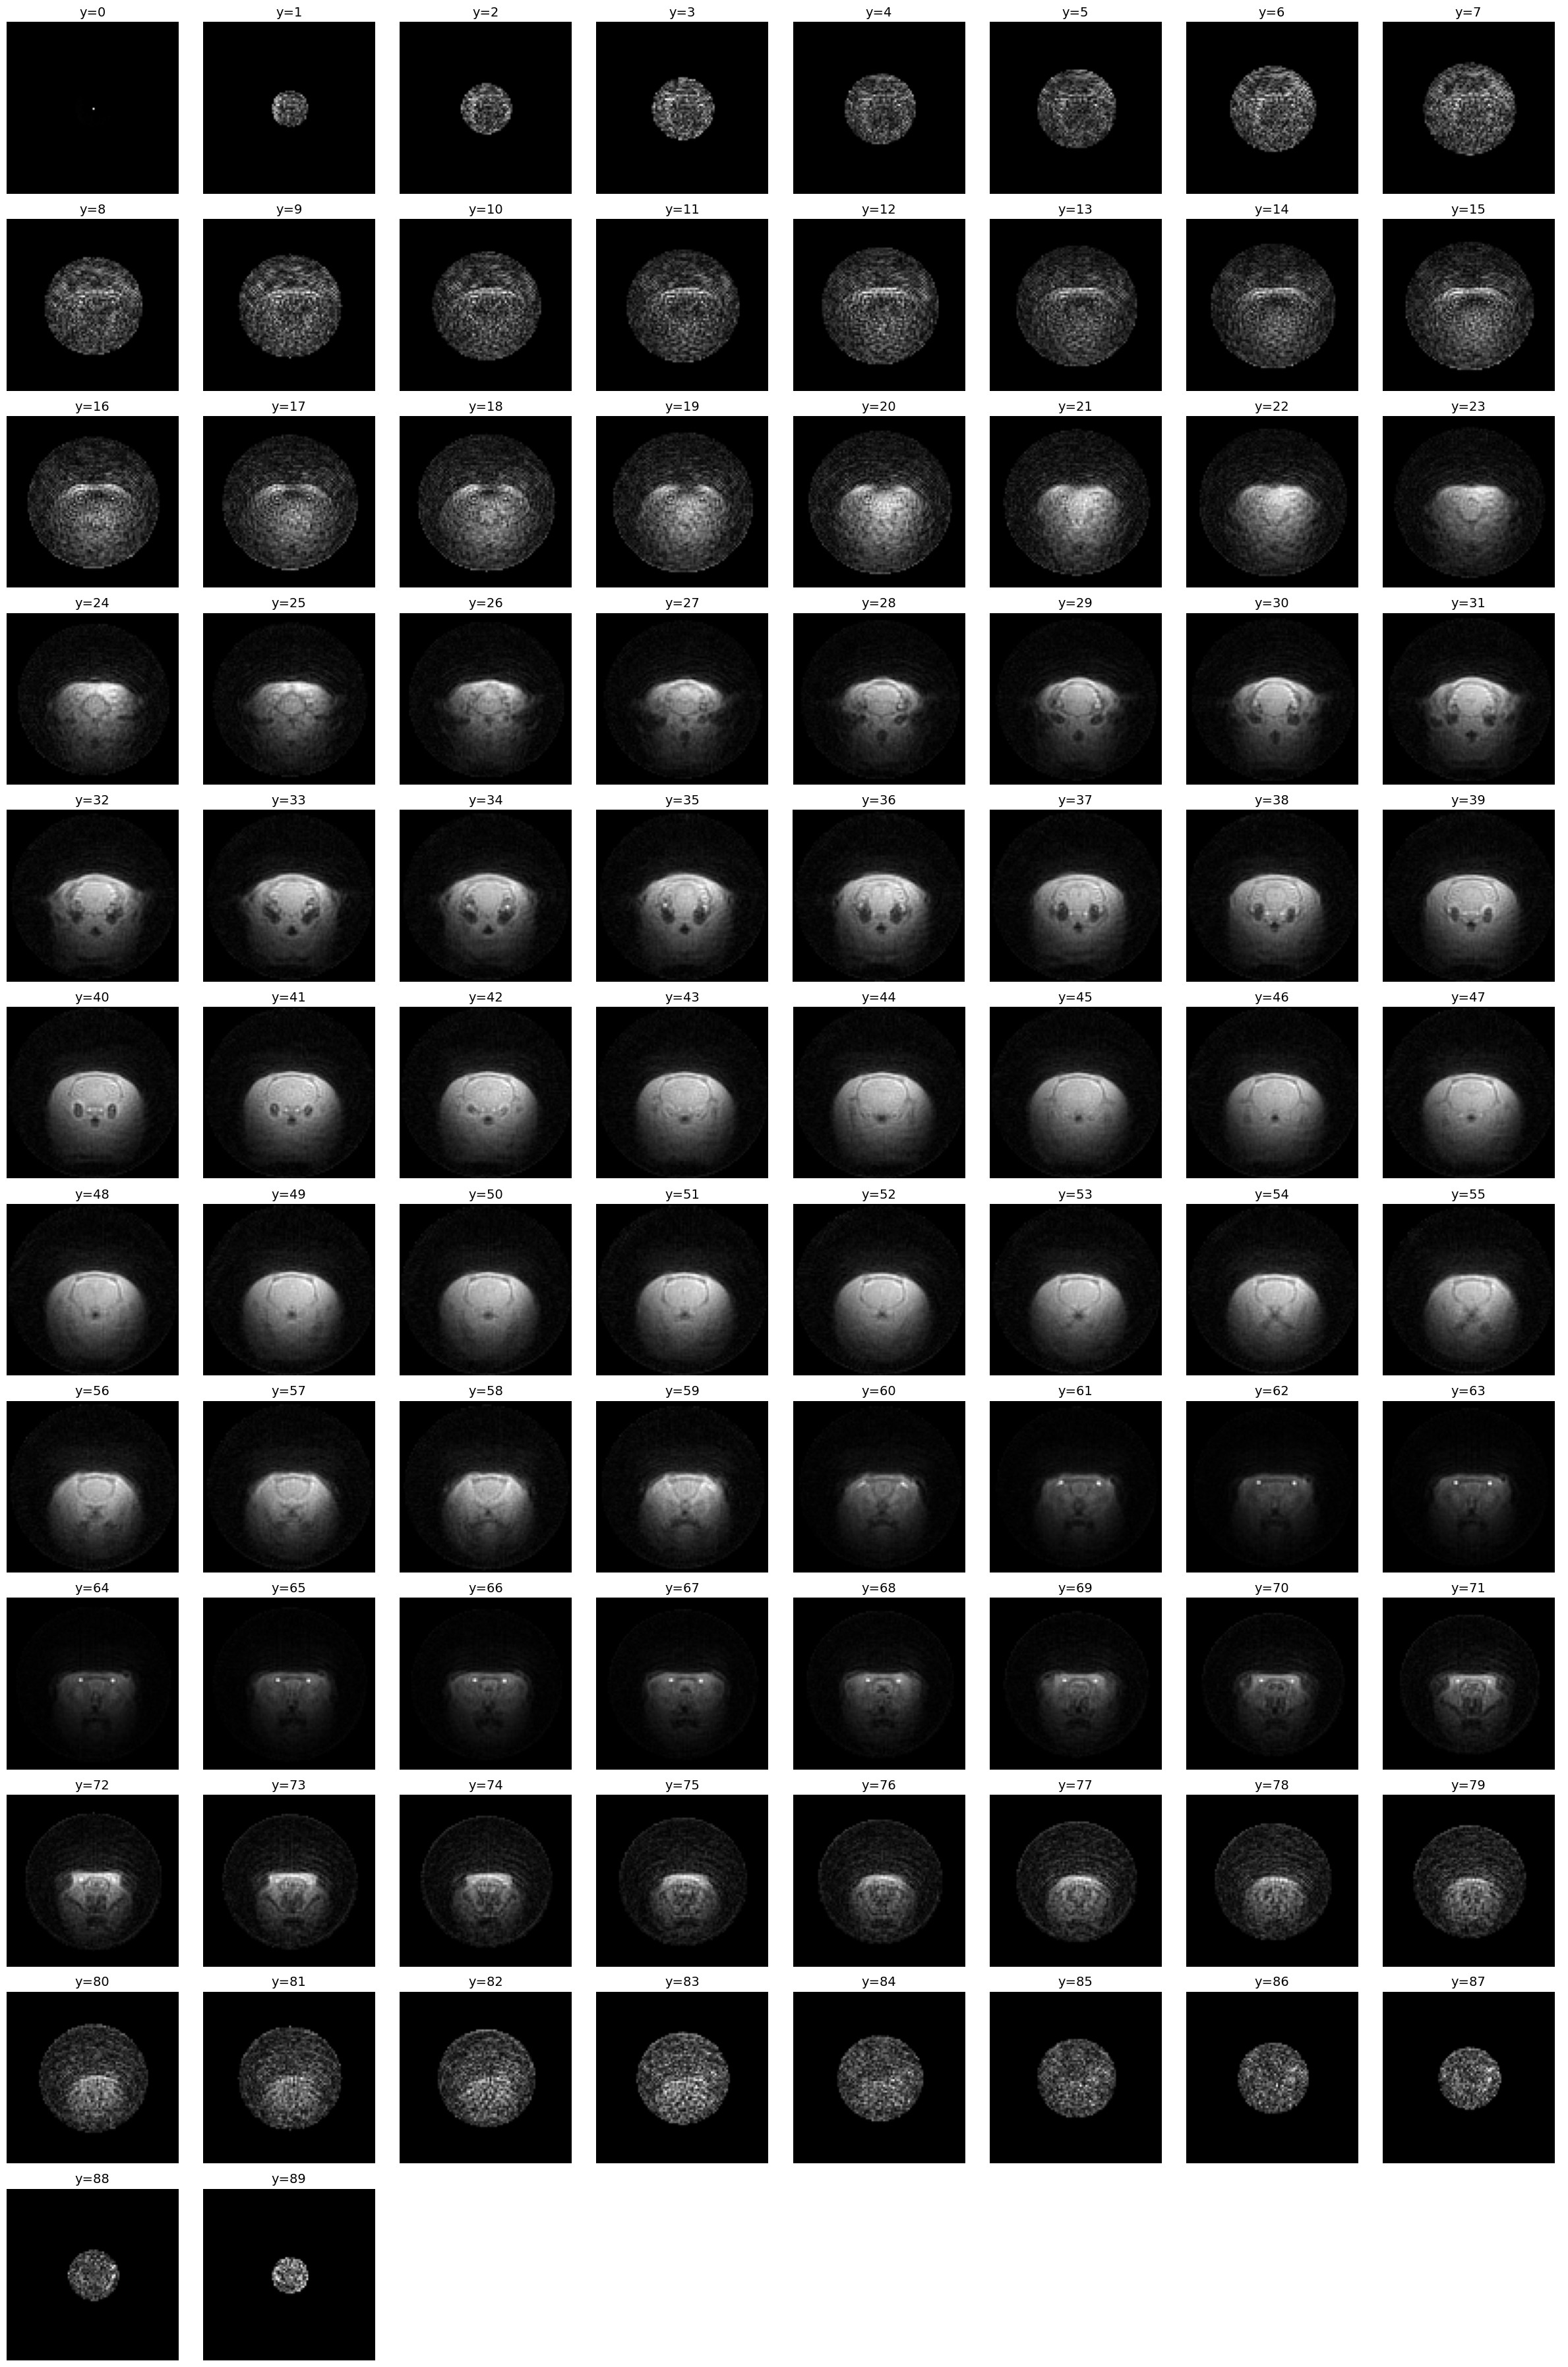

[INFO] Creating motion plots…


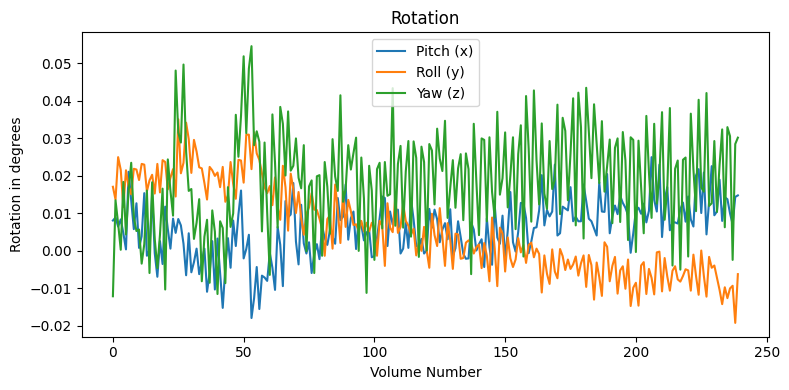

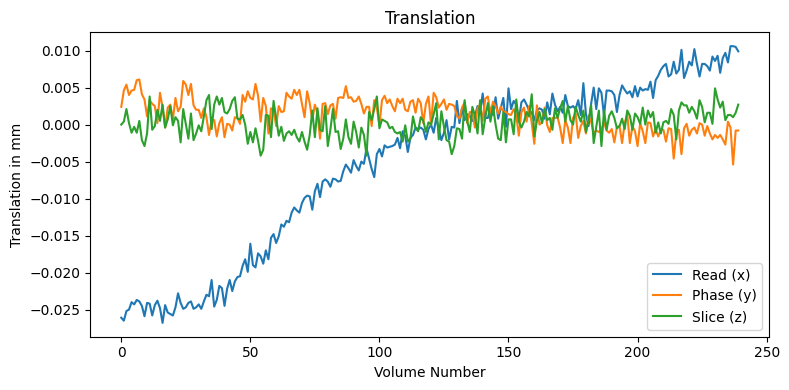

In [26]:
motion_input = "func_norm.nii.gz" if normalise_enabled else "func.nii.gz"

if is_step_enabled("motion_correction"):
    print_header("Applying Motion Correction on raw functional data and plotting motion parameters", bcolors.HEADER)

    if os.path.exists("mc_func.nii.gz"):
        print_statement("Motion Corrected functional data exists. Skipping motion correction.", bcolors.OKGREEN)
    else:
        motion_correction("middle_vol.nii.gz", motion_input, output_prefix="mc_func")

    # Display of the motion corrected image and motion parameters
    view_images("mc_func.nii.gz", cmap="gray")
    plot_motion_parameters("motion.1D")
else:
    print_statement("⏭️ Motion Correction not executed", bcolors.NOTIFICATION)

# Mean Motion-Corrected Image

In [27]:
print_statement(f"Analysis folder: {analysis_dir}", bcolors.NOTIFICATION)
analysis_dir.mkdir(parents=True, exist_ok=True)
os.chdir(analysis_dir)

mc_func_file = analysed_func_dir / "mc_func.nii.gz"
run_step(["mean_mc_func.nii.gz"], [mc_func_file], mean_image, str(mc_func_file), "mean_mc_func.nii.gz")

Analysis folder: /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis
[OK] Mean image saved -> mean_mc_func.nii.gz


'mean_mc_func.nii.gz'

# Converting Structural Data into NIFTI and Processing it

Analysed Data Path: /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/37anatomy

**************************************************************************************************************************************
                                             Converting Bruker to NIFTI: Structural Data                                              
**************************************************************************************************************************************



/Users/pschmidt/miniforge3/envs/fmri/lib/python3.11/site-packages/brkraw/lib/loader.py:951: UserWarning: Unexpected version[VisuVersion];8
  warnings.warn('Unexpected version[VisuVersion];{}'.format(version), UserWarning)


NifTi file is generated... [RGRO_261026_0224_RN_SD_468_1-37-1-anatomy-(E37)]
Fixing orientation to LPI
[OK] Bruker → NIFTI workflow completed.
Cleaning the structural image by manually creating mask
Please create a mask for the structural image and save it as mask_struct.nii.gz


Exception ignored while finalizing file <_io.TextIOWrapper name=5 mode='w' encoding='UTF-8'>:
Traceback (most recent call last):
  File "/Users/pschmidt/fsl/lib/python3.14/threading.py", line 1028, in run
    del self._target, self._args, self._kwargs
OSError: [Errno 9] Bad file descriptor


[OK] Masked file saved → cleaned_struct.nii.gz


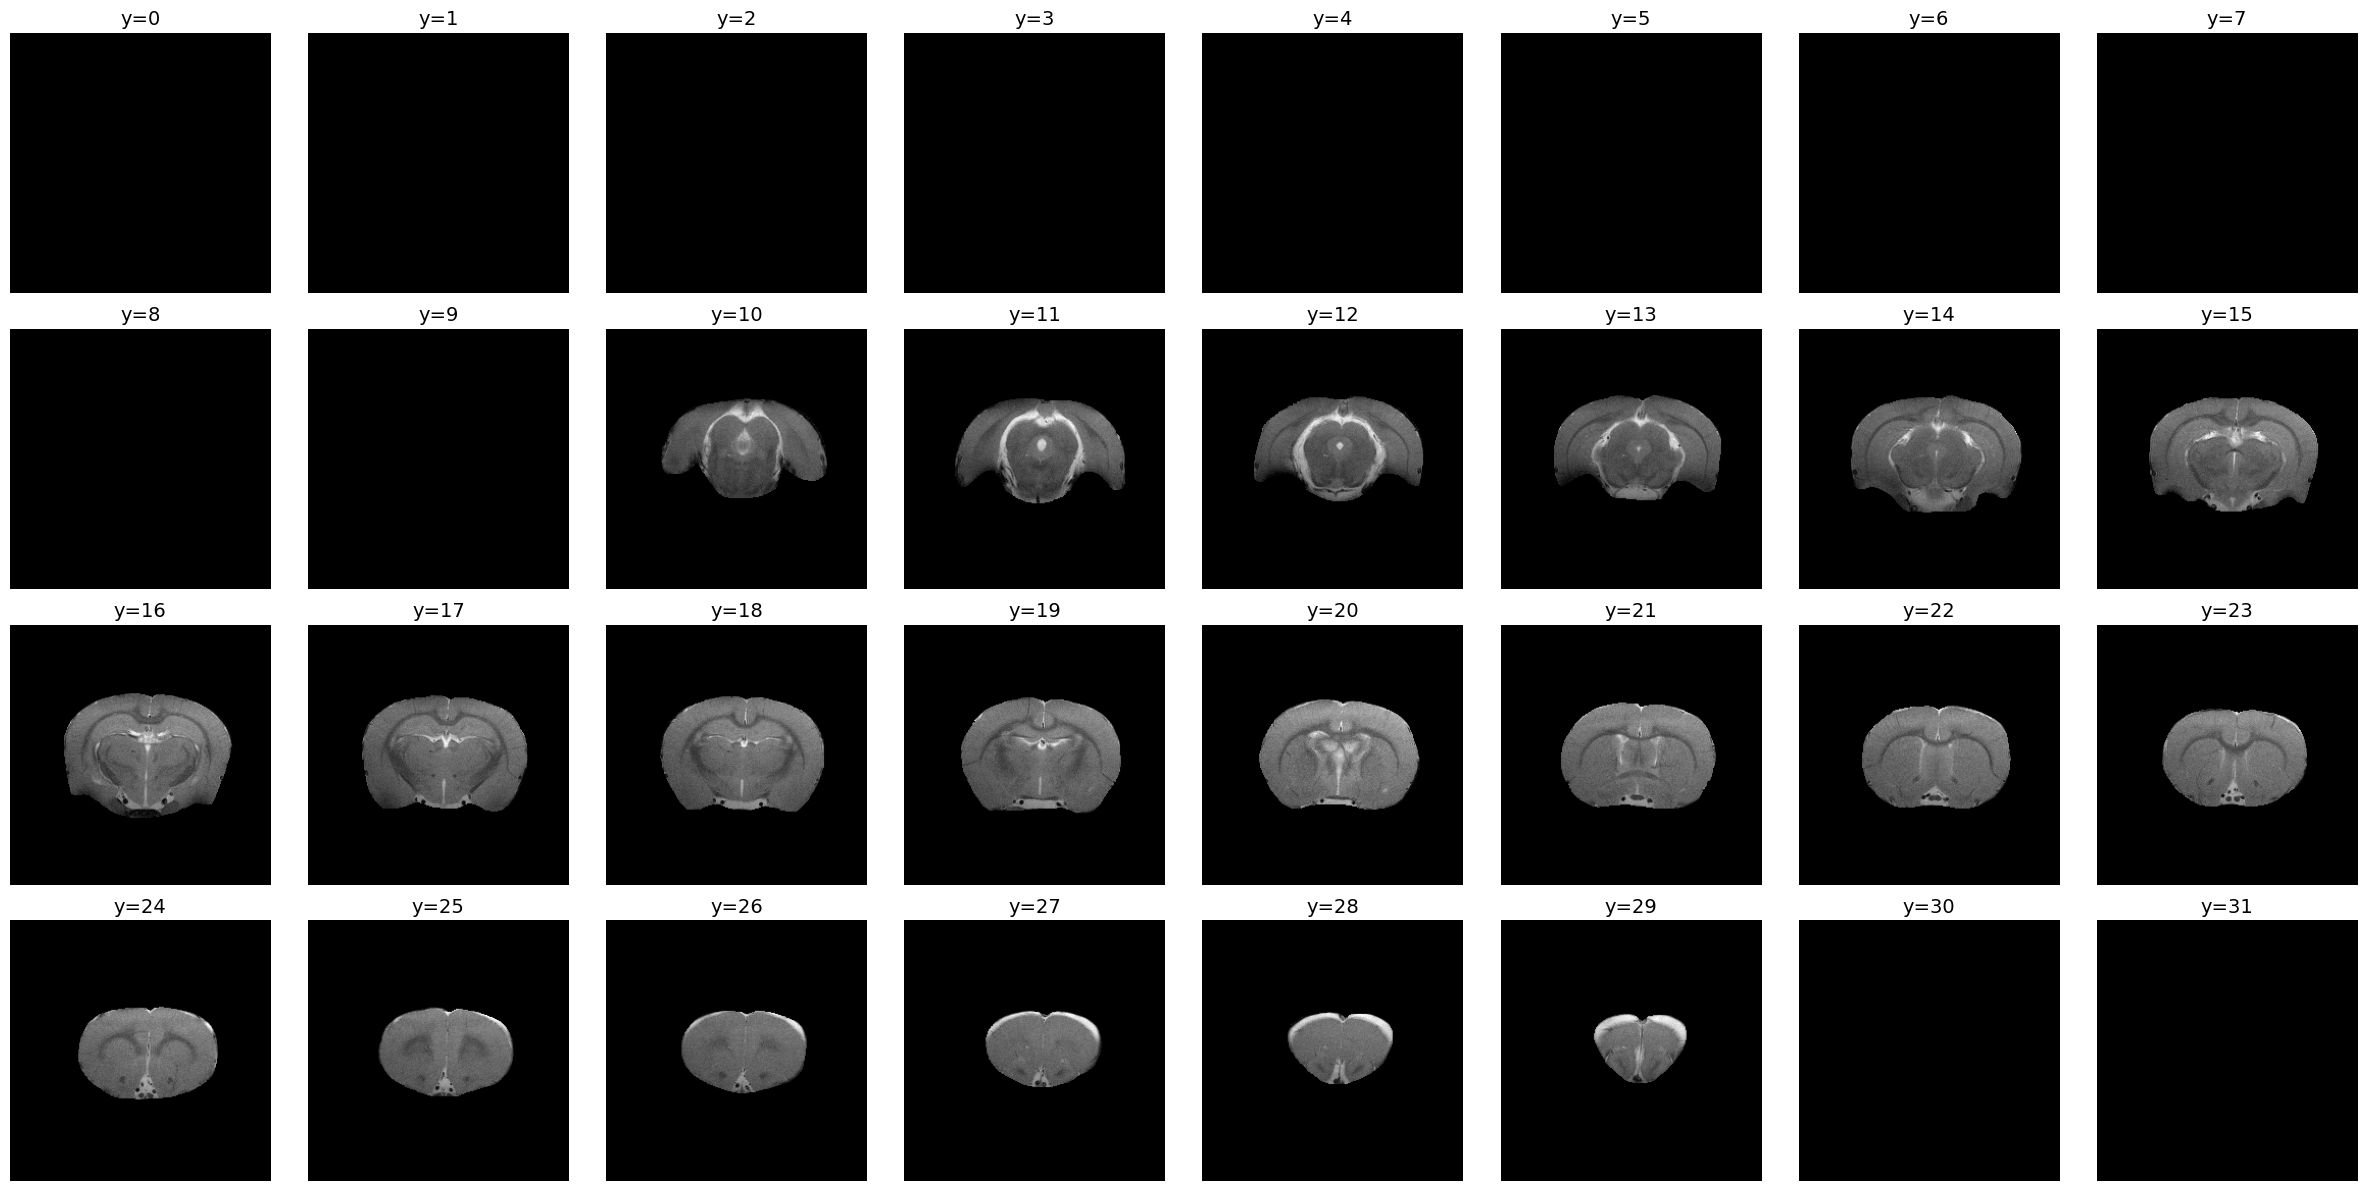

In [28]:
print_statement(f"Analysed Data Path: {analysed_struct_dir}", bcolors.NOTIFICATION)
analysed_struct_dir.mkdir(parents=True, exist_ok=True)
os.chdir(analysed_struct_dir)

if is_step_enabled("bruker_to_nifti"):
    print_header("Converting Bruker to NIFTI: Structural Data", bcolors.HEADER)

    nifti_file = analysed_struct_dir / "struct.nii.gz"
    if nifti_file.exists():
        print_statement("NIfTI file already exists. Skipping conversion.", bcolors.OKGREEN)
    else:
        bruker_to_nifti(in_path, struct_scan_number, "struct.nii.gz")

else:
    print_statement("⏭️ Data Conversion Step not executed, May cause trouble in running further analysis", bcolors.NOTIFICATION)


#Cleaning the structural image by masking it with a manually created mask

if is_step_enabled("masking_file"):
    print_statement("Cleaning the structural image by manually creating mask", bcolors.NOTIFICATION)
    
    if os.path.exists("cleaned_struct.nii.gz"):
        print_statement("Structural Image for Coregistration exists.", bcolors.OKGREEN)
    else:
        print_statement("Please create a mask for the structural image and save it as struct_mask.nii.gz", bcolors.NOTIFICATION)
        subprocess.run(["fsleyes", "struct.nii.gz", os.path.join(analysed_func_dir, "middle_vol.nii.gz")])
        masking_file("struct.nii.gz", str(structural_mask_file(analysed_struct_dir)), "cleaned_struct.nii.gz")

    structural_file_for_coregistration = os.path.join(analysed_struct_dir, "cleaned_struct.nii.gz")    
    view_images("cleaned_struct.nii.gz", cmap="gray")
    
    #Further shrinking the mask for structural image to get better coregistration results as structural image has high spatial resolution than functional image
    

else:
    print_statement("⏭️ Masks not generated, will not get cleaned data in further pipeline", bcolors.NOTIFICATION)    
    structural_file_for_coregistration = os.path.join(analysed_struct_dir, "struct.nii.gz")    
    view_images("struct.nii.gz", cmap="gray")

In [29]:
# The stimulation analysis only needs the motion corrected data, the mask and the structural image
session_file = save_session(
    analysis_dir,
    in_path=in_path, subject_id=subject_id, func_scan_numbers=func_scan_numbers, struct_scan_number=struct_scan_number,
    analysed_func_dir=analysed_func_dir, analysed_struct_dir=analysed_struct_dir, analysis_dir=analysis_dir,
    mask_file=mask_file, structural_file_for_coregistration=structural_file_for_coregistration, tr=tr,
    drop_vols=drop_vols, scan_normalization=str(analysed_func_dir / "scan_normalization.csv") if normalise_enabled else None,
    scan_info={num: {k: p[k] for k in ("NoOfRepetitions", "VolTR", "BlockTriggerMode", "StartOfScanTrigger", "TriggerPulseDuration_ms", "volumes_per_block", "block_onsets")}
               for num, p in params_all.items()})
print_statement(f"[OK] Session saved: {session_file}", bcolors.OKGREEN)

[OK] Session saved: /Volumes/pschmidt/fmri_analysis/AnalysedData/Sordino_converted/RGRO_261026_0224_RN_SD_468/stitched_71_sordino_norm/analysis/session.json
